<a href="https://colab.research.google.com/github/marzanebadi-star/CVPR_Mid/blob/main/CNN_23_52507_2(C).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#CNN for Brain Tumor MRI Classification
###Import Libraries

In [ ]:
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import os, random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


##Load and Explore Dataset
### BRISC 2025 brain MRI dataset.It has 4 classes(glioma,meningma,pituitary,no tumor)

######Dataset Information
**Dataset:** BRISC 2025 (Kaggle: briscdataset/brisc2025)
**License:** Attribution 4.0 International (CC BY 4.0)
**Paper:** BRISC: Annotated Dataset for Brain Tumor Segmentation and Classification (2025)
**Paper DOI: https://doi.org/10.48550/arXiv.2506.14318

In [ ]:
import kagglehub
path = kagglehub.dataset_download("briscdataset/brisc2025")
print("Path to dataset files:", path)

# find the classification_task folder (the segmentation folder is not needed)
cls_root = None
for root, dirs, files in os.walk(path):    #go through all the folders of the dataset
    if os.path.basename(root) == "classification_task":  #check the folder name
        cls_root = root
        break
print("Classification folder:", cls_root)
print(os.listdir(cls_root))

Using Colab cache for faster access to the 'brisc2025' dataset.
Path to dataset files: /kaggle/input/brisc2025
Classification folder: /kaggle/input/brisc2025/brisc2025/classification_task
['test', 'train']


##Data Preprocessing and Augmentation
I resized all the images to 128 x 128 and changed them to tensors, so all pixel values are between 0 and 1. For the training images I also flipped, rotated and changed the brightness a little, so the model does not just memorize them. Validation and test images are only resized. I split the test folder into 500 validation and 500 test images.

In [ ]:
import torchvision.transforms as transforms
from torch.utils.data import random_split

size = 128      #every image is resized to 128 x 128
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_folder = cls_root + '/train'
test_folder = cls_root + '/test'

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
val_test_data = datasets.ImageFolder(test_folder,transform = val_transform)

# Split original test dataset into validation (50%) and test (50%)
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size]
)
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , train_data.class_to_idx)

Dataset Summary
Train Data:  5000
Validation Data:  500
Test Data:  500
Classess and Indices:  {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}



### Hyperparameters and Data Loaders
Batch size 32 (common default, fits easily in GPU memory), Adam optimizer with learning rate 0.001 (standard starting value), 23 epochs (the curves become stable at the end without overfitting) and Cross-Entropy loss for multi-class classification.

In [ ]:
batch_size = 32
learning_rate=1e-3
epoch_number = 23
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

##Define CNN Architecture
CNN has two convolution layers (64 and 128 filters). ReLU is used after each one, and four max pooling layers make the image smaller, from 128 x 128 to 7 x 7. Then the features are flattened and go through two linear layers (256 units, then 4 outputs for the 4 classes). The model has 1,682,564 parameters and is 6.42 MB.

In [ ]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.MaxPool2d(2),     #extra pooling layer make the image 7x7
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*7*7, 256),  #128*7*7=6272 values in one line
        nn.ReLU(),                 #6272->256
        nn.Linear(256, 4)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

Model Summary

In [ ]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,size,size));  #input = 3 channels,128x128

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 126, 126]           1,792
              ReLU-2         [-1, 64, 126, 126]               0
         MaxPool2d-3           [-1, 64, 63, 63]               0
            Conv2d-4          [-1, 128, 61, 61]          73,856
              ReLU-5          [-1, 128, 61, 61]               0
         MaxPool2d-6          [-1, 128, 30, 30]               0
         MaxPool2d-7          [-1, 128, 15, 15]               0
         MaxPool2d-8            [-1, 128, 7, 7]               0
           Flatten-9                 [-1, 6272]               0
           Linear-10                  [-1, 256]       1,605,888
             ReLU-11                  [-1, 256]               0
           Linear-12                    [-1, 4]           1,028
Total params: 1,682,564
Trainable params: 1,682,564
Non-trainable params: 0
---------------------------

##Training Loop with Validation
In each epoch the model first learns from the training images and then it is checked on the validation images. I save the loss and accuracy of both, to draw the curves.

In [ ]:

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/23] | Train Loss: 0.8661 | Train Accuracy: 65.16% | Val Loss: 0.6940 | Val Accuracy: 71.60%
Epoch [2/23] | Train Loss: 0.5910 | Train Accuracy: 76.66% | Val Loss: 0.8914 | Val Accuracy: 67.40%
Epoch [3/23] | Train Loss: 0.4984 | Train Accuracy: 80.62% | Val Loss: 0.4404 | Val Accuracy: 81.00%
Epoch [4/23] | Train Loss: 0.4132 | Train Accuracy: 83.92% | Val Loss: 0.4516 | Val Accuracy: 81.80%
Epoch [5/23] | Train Loss: 0.3531 | Train Accuracy: 86.24% | Val Loss: 0.3352 | Val Accuracy: 86.60%
Epoch [6/23] | Train Loss: 0.3309 | Train Accuracy: 87.32% | Val Loss: 0.4059 | Val Accuracy: 83.60%
Epoch [7/23] | Train Loss: 0.3088 | Train Accuracy: 88.20% | Val Loss: 0.3848 | Val Accuracy: 82.60%
Epoch [8/23] | Train Loss: 0.2554 | Train Accuracy: 90.38% | Val Loss: 0.2883 | Val Accuracy: 88.60%
Epoch [9/23] | Train Loss: 0.2204 | Train Accuracy: 91.82% | Val Loss: 0.2744 | Val Accuracy: 89.20%
Epoch [10/23] | Train Loss: 0.2101 | Train Accuracy: 92.14% | Val Loss: 0.2248 | Val Accura

##Visualization
These graphs show the loss and accuracy of training and validation over 23 epochs. The loss goes down (training 0.87 to 0.07, validation 0.69 to 0.11) and the accuracy goes up to about 97%. Both curves are close to each other, so the model does not overfit much. The validation curve goes up and down a little in some epochs, but it recovers.

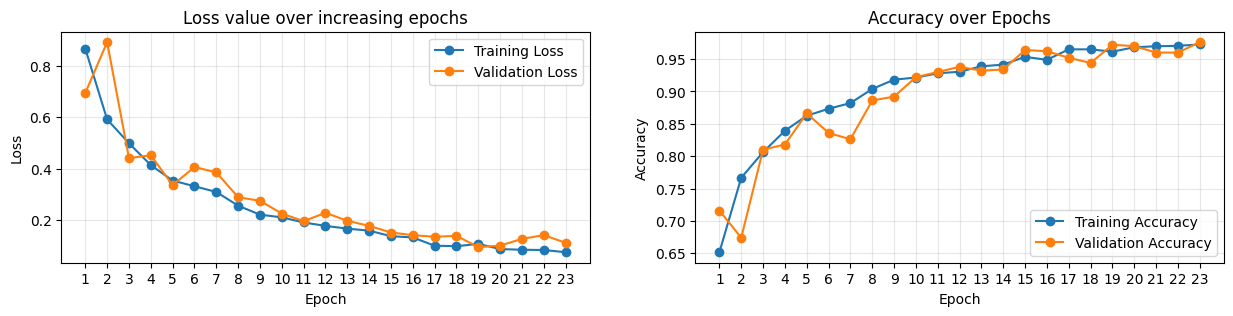

In [ ]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##Evalute Model on Test Set
The model on the 500 test images, which it has never seen. First I show 8 test images with the predicted class (Pred), the real class (Actual) and the confidence, then I calculate the test loss and accuracy.

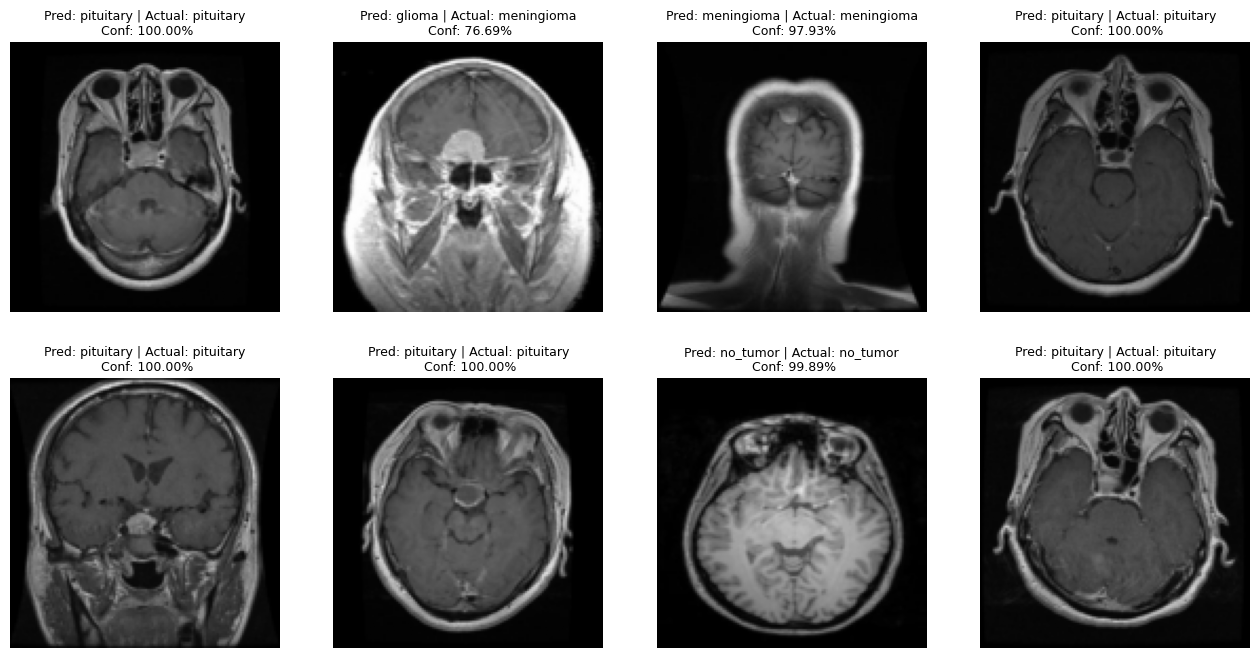

In [ ]:
plt.figure(figsize=(16,8))
for i in range(8):             #show the first 8 test images
    test_img, label = test_data[i]
    img = test_img.view(-1,3,size,size).to(device)

    output = model(img)
    pred = torch.exp(output)/torch.sum(torch.exp(output))
    confidence, index  = pred.max(-1)

    plt.subplot(2,4,i+1)  #2rows x 4 cols
    plt.imshow(test_img.view(3,size,size).permute(1,2,0))
    plt.axis('off')
    plt.title(f' Pred: {train_data.classes[index]} | Actual: {train_data.classes[label]} \n Conf: {confidence.item()*100:0.2f}%', fontsize=9)
plt.show()

In [ ]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.13 , Test Accuracy: 97.00%


##Precision,Recall and F1-score

              precision    recall  f1-score   support

      glioma       0.95      0.96      0.95       119
  meningioma       0.96      0.95      0.96       160
    no_tumor       1.00      0.97      0.99        68
   pituitary       0.98      1.00      0.99       153

    accuracy                           0.97       500
   macro avg       0.97      0.97      0.97       500
weighted avg       0.97      0.97      0.97       500

[[114   5   0   0]
 [  5 152   0   3]
 [  1   1  66   0]
 [  0   0   0 153]]


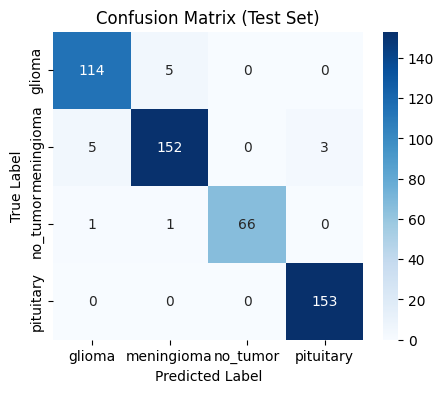

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

preds, labels = [], []
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(-1).cpu().tolist()
        labels += y.tolist()

# precision, recall and F1-score of every class
print(classification_report(labels, preds, target_names=train_data.classes))

# confusion matrix (rows = real class, columns = predicted class)
cm = confusion_matrix(labels, preds)
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_data.classes, yticklabels=train_data.classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Test Set)')
plt.show()

##Save and Load Model weights

In [ ]:
torch.save(model.state_dict(),'model.pth')
print("Model file size (MB):", round(os.path.getsize('model.pth') / (1024*1024), 2))

saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()
summary(saved_model,(3,size,size))

Model file size (MB): 6.42
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 126, 126]           1,792
              ReLU-2         [-1, 64, 126, 126]               0
         MaxPool2d-3           [-1, 64, 63, 63]               0
            Conv2d-4          [-1, 128, 61, 61]          73,856
              ReLU-5          [-1, 128, 61, 61]               0
         MaxPool2d-6          [-1, 128, 30, 30]               0
         MaxPool2d-7          [-1, 128, 15, 15]               0
         MaxPool2d-8            [-1, 128, 7, 7]               0
           Flatten-9                 [-1, 6272]               0
           Linear-10                  [-1, 256]       1,605,888
             ReLU-11                  [-1, 256]               0
           Linear-12                    [-1, 4]           1,028
Total params: 1,682,564
Trainable params: 1,682,564
Non-trainable params: 0


##Misclassified Images
The images that the model predicted wrongly on the test set are shown below with the real class (True) and the predicted class (Pred). This shows which kind of images are difficult for the model

Total misclassified samples: 15


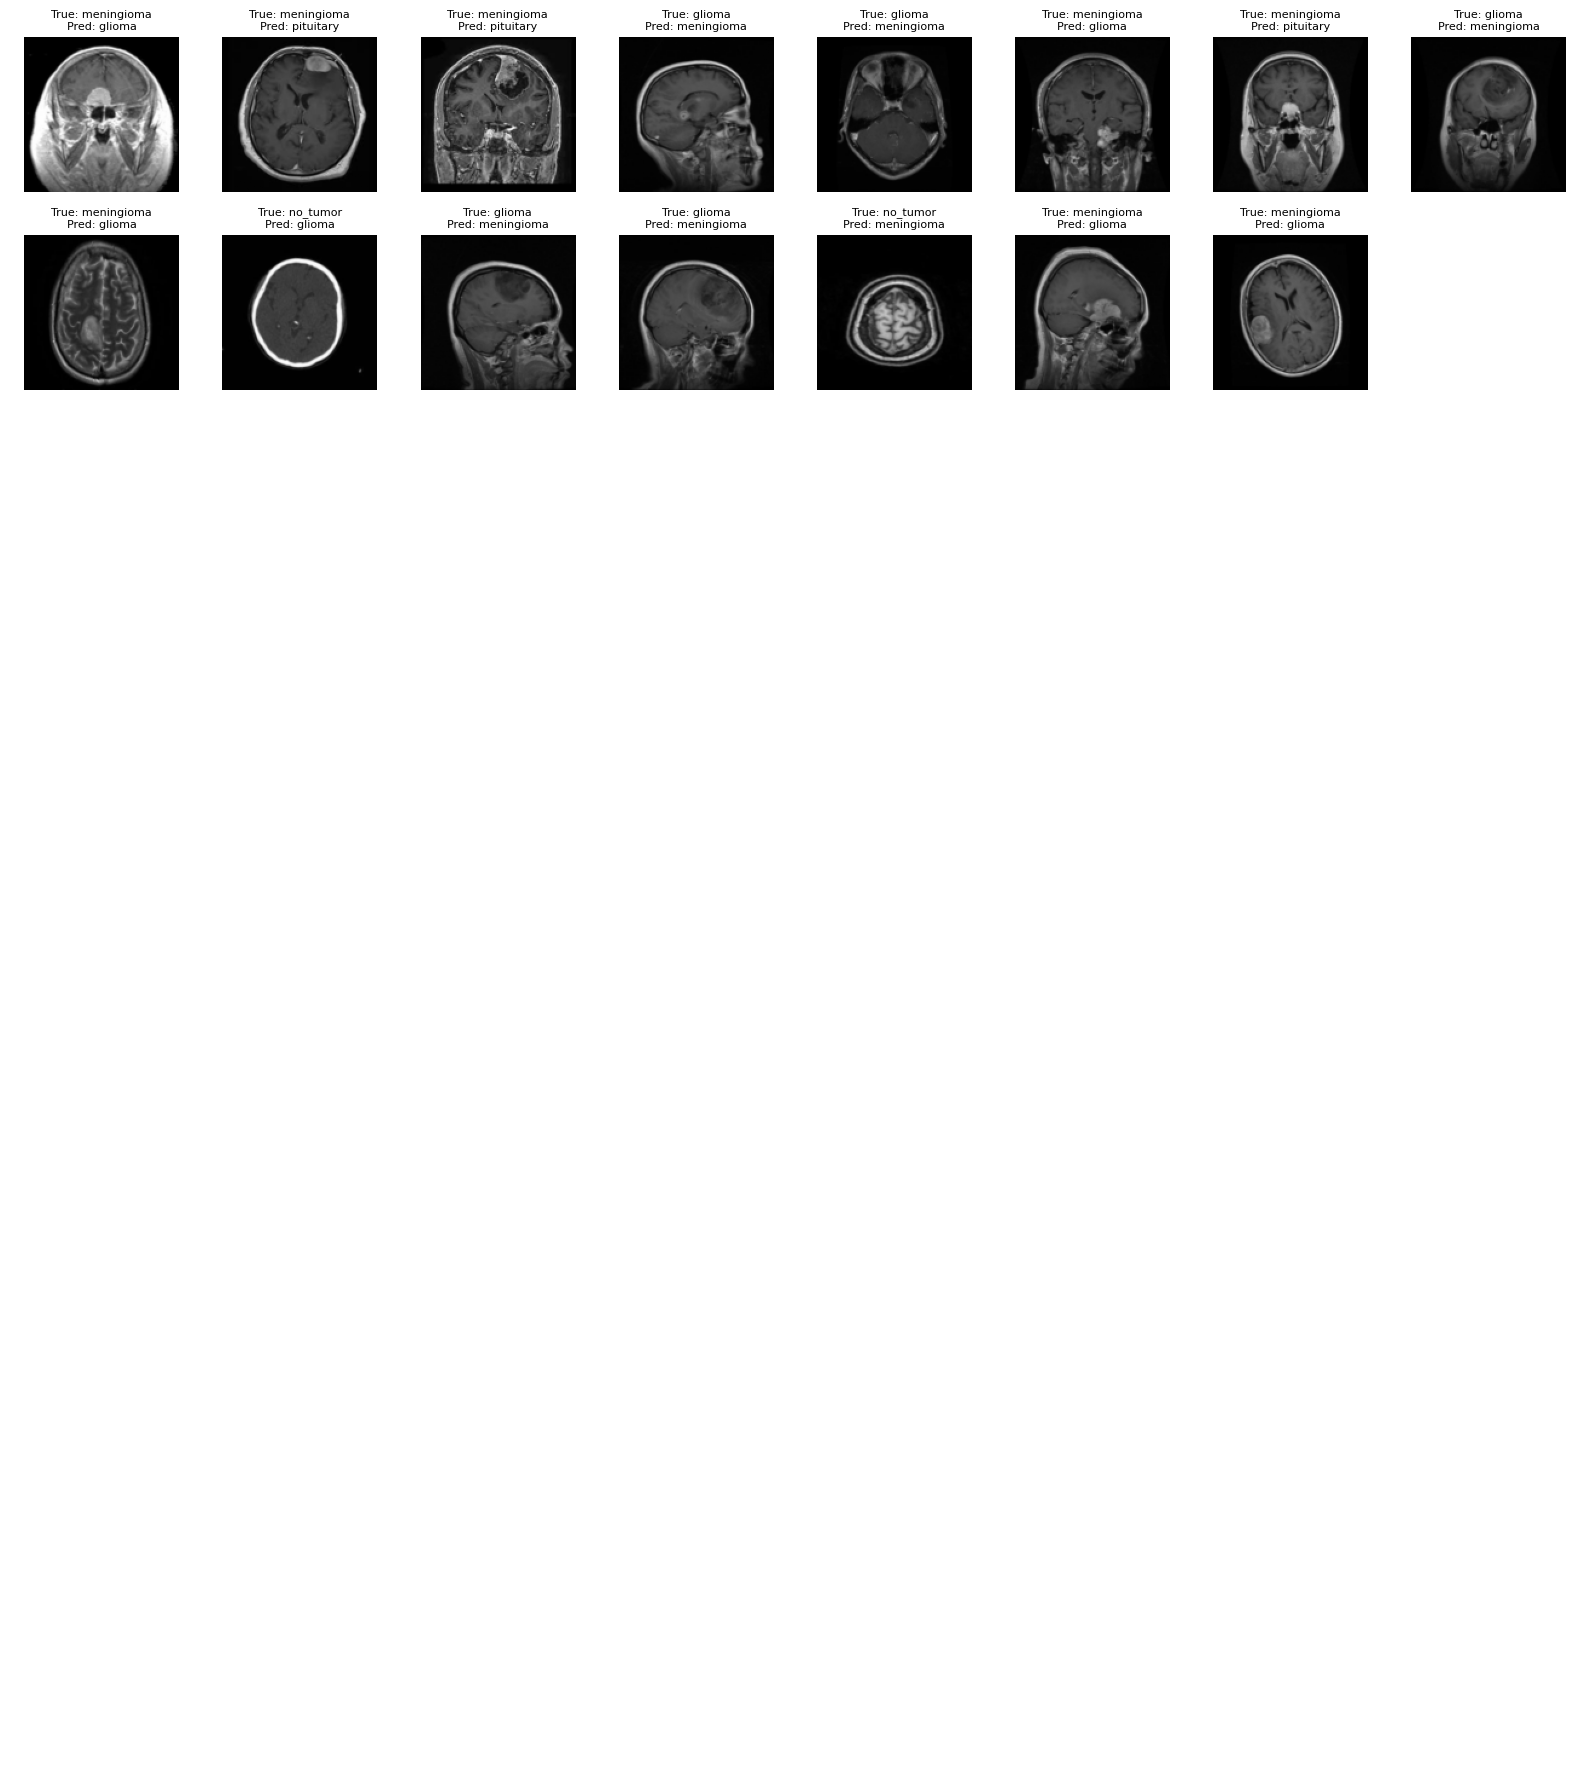

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import torch

class_names = train_data.classes

model.eval()
misclassified = []       #wrong prediction will be saved here
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_dl:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)  #prediction class for every image

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        for img, true, pred in zip(images, labels, preds):
            if true.item() != pred.item():
                misclassified.append((img.cpu(), true.item(), pred.item()))

print(f"Total misclassified samples: {len(misclassified)}")
#grid of 9 rows x 8 cols
num_rows = 9
num_cols = 8
num_to_show = min(num_rows * num_cols, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2, num_rows * 2))
axes = axes.flatten()

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    img = img.permute(1, 2, 0).numpy()

    axes[idx].imshow(img)
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}", fontsize=8)
    axes[idx].axis('off')

for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

##Duplicate Images

In [ ]:
import hashlib

# all images of both folders together
all_samples = train_data.samples + val_test_data.samples

hashes = {}
for file_path, label in all_samples:
    with open(file_path, 'rb') as f:
        h = hashlib.md5(f.read()).hexdigest()
    hashes.setdefault(h, []).append(file_path)

total_images = len(all_samples)
unique_images = len(hashes)
total_duplicates = total_images - unique_images

print("Total images (train + test):", total_images)
print("Unique images:", unique_images)
print("Total duplicate images:", total_duplicates)

Total images (train + test): 6000
Unique images: 5950
Total duplicate images: 50


# **Analysis & Discussion of Results**

In this project, a custom CNN with two convolution layers (64 and 128 filters) was trained using a batch size of 32 and 23 epochs to classify brain tumor MRI images from the BRISC 2025 dataset into four classes. The model reached 97.00% accuracy on the unseen test set (485 of 500 images correct), with a final training accuracy of 97.26% and a validation accuracy of 97.60%. The training loss decreased steadily from 0.87 to 0.07, and the validation loss followed it closely, from 0.69 to 0.11, so the model learned useful features without overfitting. The validation curve was shaky at some epochs, for example at epoch 2 the validation accuracy dropped to 67.40%, but it recovered in the next epochs. From the classification report, the model works best on the "pituitary" class (precision 0.98, recall 1.00, F1-score 0.99) and the "no_tumor" class (precision 1.00, F1-score 0.99), and the weakest class is "glioma" (F1-score 0.95). The confusion matrix shows that 5 glioma images were predicted as meningioma and 5 meningioma images were predicted as glioma, which are the biggest mistakes of the model, and 3 meningioma images were predicted as pituitary. The model made 15 wrong predictions out of 500 images. The images in this dataset are taken from different views of the head, so the same tumor type can look quite different, and glioma and meningioma can look similar in some slices, which is hard for a small CNN. Overall, the model performs well, but the result may be slightly optimistic because the dataset has 50 duplicate images and slices from the same patient can appear in both the training and test data.

# **Conclusions & Future Work**

A custom CNN was successfully developed to classify brain tumor MRI images into glioma, meningioma, pituitary tumor and no tumor. The model reached a test accuracy of 97.00% and showed good learning ability, with both training and validation accuracy close to 97%, which shows that even a simple CNN can find useful patterns in medical images. Although the model performed well, some confusion between tumor types was observed, mainly between glioma and meningioma. The trained weights were saved as model.pth (6.42 MB) and loaded back successfully.

For future work, the performance can be improved by using a deeper network or transfer learning models such as ResNet or EfficientNet and by applying stronger data augmentation. Splitting the data by patient, tuning the hyperparameters and using early stopping or a learning rate scheduler can also give more reliable results, because the validation curve was not smooth at some epochs. In addition, explainability methods like Grad-CAM could show which regions of the MRI influenced the predictions, which would make the model more useful in real medical applications.